# Lab 2 · Bayes' rule with natural frequencies

**Level:** Levels 1–2 (Going deeper: Level 3) · **Prerequisites:** L1-04 (count within a condition), L2-04 (conditional probability), L2-05 (reverse a condition with Bayes' rule)

What you'll learn:

- Why $P(\text{positive}\mid\text{condition})$ and $P(\text{condition}\mid\text{positive})$ are different numbers.
- How to compute a posterior by counting an imaginary group of 10,000 people.
- Why a rare condition makes most positive results false alarms. This is the base-rate fallacy.
- How to update twice with two tests, and why that needs a conditional-independence assumption.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/02-bayes.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from qcai import science as s
from qcai.viz import show

plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

:::{note}
The people, test, and rates here are made up. All probabilities come from `qcai.science.bayes`, the reviewed course engine.
:::

## 1 · Predict → Run → Explain: one positive test

A condition affects 1 person in 100. A test finds it in 90 % of people who have it. This is the test's sensitivity. The test also wrongly flags 5 % of people who do not have it. This is its false-positive rate.

**Predict.** Someone tests positive. Is the chance they have the condition closer to 90 %, 50 %, or 15 %?

In [3]:
N = 10_000

def natural_frequencies(prior, sens, fp, n=N):
    # Whole numbers of people in each branch; the four counts always add to n.
    sick = round(n * prior)
    tp = round(sick * sens)
    healthy = n - sick
    fpos = round(healthy * fp)
    return dict(sick=sick, healthy=healthy, tp=tp, fn=sick - tp, fp=fpos, tn=healthy - fpos)

PRIOR, SENS, FP = 0.01, 0.90, 0.05
r = s.bayes(PRIOR, SENS, FP)
c = natural_frequencies(PRIOR, SENS, FP)
print(f"engine:  P(positive) = {r['positive']:.4f},  P(condition | positive) = {r['posterior']:.4f}")
print(f"counts:  of {N:,} people, {c['sick']} have the condition and {c['tp']} of them test positive;")
print(f"         {c['healthy']:,} do not, and {c['fp']} of them test positive.")
print(f"         posterior by counting = {c['tp']} / ({c['tp']} + {c['fp']}) = {c['tp'] / (c['tp'] + c['fp']):.4f}")

engine:  P(positive) = 0.0585,  P(condition | positive) = 0.1538
counts:  of 10,000 people, 100 have the condition and 90 of them test positive;
         9,900 do not, and 495 of them test positive.
         posterior by counting = 90 / (90 + 495) = 0.1538


In [4]:
assert (c["sick"], c["tp"], c["fn"], c["fp"], c["tn"]) == (100, 90, 10, 495, 9405)
assert sum(c[k] for k in ("tp", "fn", "fp", "tn")) == N
assert math.isclose(r["posterior"], 90 / 585)                 # about 0.154
assert math.isclose(c["tp"] / (c["tp"] + c["fp"]), r["posterior"])
assert r["posterior"] < 0.2 < SENS                            # base-rate fallacy: far below the sensitivity
print("Natural-frequency checks passed.")

Natural-frequency checks passed.


**Explain.** There are 585 positive results. Only 90 of them come from people with the condition. So the posterior is $90/585\approx0.154$. This is a conditional probability: you count only inside the positive group [@openstax]. The test is good, but the condition is rare. Among the 9,900 healthy people, 5 % test positive: that is 495 false alarms. Among the 100 sick people, 90 % test positive: that is 90. The false alarms win. The starting rate is called the *prior*, or base rate. Ignoring it and answering "90 %" is called the base-rate fallacy.

## 2 · An icon array of 10,000 people

Each small square is one person. The squares are sorted into four groups. Move the prior slider. Use the dropdown to choose the test's sensitivity and false-positive rate. The title shows the engine's posterior.

In [5]:
COL = {"tp": "#c0392b", "fn": "#f1948a", "fp": "#e67e22", "tn": "#d5d8dc"}
NAMES = {"tp": "has condition, positive", "fn": "has condition, negative",
         "fp": "no condition, positive (false alarm)", "tn": "no condition, negative"}
PRIORS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
TESTS = [(sens, fp) for sens in (0.80, 0.90, 0.99) for fp in (0.01, 0.05, 0.10)]

def colorscale(cnt):
    # z holds the person index 0..9999; people are ordered tp, fn, fp, tn, so a stepped
    # colorscale with breaks at the cumulative counts colours each group.
    edges = np.cumsum([cnt["tp"], cnt["fn"], cnt["fp"]])
    out, lo = [], 0.0
    for key, edge in zip(("tp", "fn", "fp", "tn"), list(edges) + [N]):
        hi = 1.0 if key == "tn" else min(1.0, max(0.0, (edge - 0.5) / (N - 1)))
        out += [[lo, COL[key]], [hi, COL[key]]]
        lo = hi
    return out

def title(prior, sens, fp):
    cnt = natural_frequencies(prior, sens, fp)
    post = s.bayes(prior, sens, fp)["posterior"]
    return (f"prior {prior:g}, sensitivity {sens:g}, false-positive {fp:g}: "
            f"{cnt['tp']} true vs {cnt['fp']} false positives → P(condition | +) = {post:.3f}")

def prior_slider(sens, fp, active):
    steps = [dict(method="update", label=f"{p:g}",
                  args=[{"colorscale": [colorscale(natural_frequencies(p, sens, fp))]},
                        {"title.text": title(p, sens, fp)}]) for p in PRIORS]
    return dict(active=active, steps=steps, currentvalue=dict(prefix="prior (base rate): "),
                pad=dict(t=30))

start = PRIORS.index(PRIOR)
z = np.arange(N).reshape(100, 100).tolist()
fig = go.Figure(go.Heatmap(z=z, colorscale=colorscale(c), zmin=0, zmax=N - 1, showscale=False,
                           xgap=0.6, ygap=0.6, hovertemplate="person %{z}<extra></extra>"))
for key in ("tp", "fn", "fp", "tn"):                       # legend entries only
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=NAMES[key],
                             marker=dict(symbol="square", size=12, color=COL[key])))
buttons = [dict(method="update", label=f"sensitivity {sn:g}, false-positive {f:g}",
                args=[{"colorscale": [colorscale(natural_frequencies(PRIOR, sn, f))]},
                      {"sliders": [prior_slider(sn, f, start)], "title.text": title(PRIOR, sn, f)}])
           for sn, f in TESTS]
fig.update_layout(template="plotly_white", height=640, title=dict(text=title(PRIOR, SENS, FP), font=dict(size=13)),
                  xaxis=dict(visible=False), yaxis=dict(visible=False, autorange="reversed", scaleanchor="x"),
                  legend=dict(orientation="h", y=-0.02), margin=dict(t=90),
                  sliders=[prior_slider(SENS, FP, start)],
                  updatemenus=[dict(type="dropdown", buttons=buttons, active=TESTS.index((SENS, FP)),
                                    x=1.0, xanchor="right", y=1.13, yanchor="top")])
show(fig)

**Explain.** Raise the prior and watch the red block grow next to the orange one. The test has not changed. Yet the posterior rises a lot. The same evidence means more when the condition is common.

## 3 · The same reasoning as a tree

A natural-frequency tree follows the 10,000 people through two splits. First: condition or not. Then: positive or not. The slider changes the prior (sensitivity 0.9, false-positive rate 0.05).

In [6]:
labels_base = ["10,000 people", "condition", "no condition", "positive", "negative"]

def sankey_args(prior):
    cnt = natural_frequencies(prior, SENS, FP)
    vals = [cnt["sick"], cnt["healthy"], cnt["tp"], cnt["fn"], cnt["fp"], cnt["tn"]]
    labels = [f"10,000 people", f"condition: {cnt['sick']:,}", f"no condition: {cnt['healthy']:,}",
              f"positive: {cnt['tp'] + cnt['fp']:,}", f"negative: {cnt['fn'] + cnt['tn']:,}"]
    return vals, labels

vals, labels = sankey_args(PRIOR)
link_colors = ["rgba(192,57,43,0.5)", "rgba(127,140,141,0.4)", "rgba(192,57,43,0.7)",
               "rgba(241,148,138,0.6)", "rgba(230,126,34,0.7)", "rgba(213,216,220,0.7)"]
fig = go.Figure(go.Sankey(arrangement="fixed", domain=dict(x=[0, 1], y=[0.22, 1]),
    node=dict(label=labels, pad=18, thickness=16,
              color=["#566573", "#c0392b", "#7f8c8d", "#e67e22", "#aab7b8"],
              x=[0.01, 0.45, 0.45, 0.99, 0.99], y=[0.5, 0.1, 0.6, 0.15, 0.7]),
    link=dict(source=[0, 0, 1, 1, 2, 2], target=[1, 2, 3, 4, 3, 4], value=vals, color=link_colors,
              hovertemplate="%{value:,} people<extra></extra>")))
steps = []
for p in PRIORS:
    v, lab = sankey_args(p)
    cnt = natural_frequencies(p, SENS, FP)
    steps.append(dict(method="update", label=f"{p:g}",
                      args=[{"link.value": [v], "node.label": [lab]},
                            {"title.text": f"P(condition | positive) = {cnt['tp']} / {cnt['tp'] + cnt['fp']} "
                                           f"= {s.bayes(p, SENS, FP)['posterior']:.3f}"}]))
fig.update_layout(height=500, title=steps[start]["args"][1]["title.text"], margin=dict(b=20),
                  sliders=[dict(active=start, steps=steps, y=0.02, yanchor="top", currentvalue=dict(prefix="prior: "))])
show(fig)

## 4 · Posterior as a function of the prior

The next figure plots the posterior against the prior (log scale). The slider changes the sensitivity. The dropdown changes the false-positive rate. The dashed diagonal is "posterior = prior", which is what a useless test gives.

In [7]:
prior_grid = np.logspace(-4, np.log10(0.5), 120)
SENS_GRID = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
FP_GRID = [0.001, 0.01, 0.05, 0.1, 0.2]

def post_curve(sens, fp):
    return [round(s.bayes(float(p), sens, fp)["posterior"], 5) for p in prior_grid]

def sens_slider(fp, active):
    return dict(active=active, currentvalue=dict(prefix="sensitivity: "), pad=dict(t=40),
                steps=[dict(method="update", label=f"{sn:g}",
                            args=[{"y": [post_curve(sn, fp)]},
                                  {"title.text": f"sensitivity {sn:g}, false-positive rate {fp:g}"}], )
                       for sn in SENS_GRID])

s0 = SENS_GRID.index(SENS)
fig = go.Figure()
fig.add_trace(go.Scatter(x=prior_grid.tolist(), y=post_curve(SENS, FP), mode="lines",
                         line=dict(color="#c0392b", width=3), name="P(condition | positive)",
                         hovertemplate="prior %{x:.4f}<br>posterior %{y:.3f}<extra></extra>"))
fig.add_trace(go.Scatter(x=prior_grid.tolist(), y=prior_grid.tolist(), mode="lines",
                         line=dict(color="gray", dash="dash"), name="posterior = prior"))
fig.update_layout(template="plotly_white", height=470,
                  title=f"sensitivity {SENS:g}, false-positive rate {FP:g}",
                  xaxis=dict(title="prior P(condition) (log scale)", type="log"),
                  yaxis=dict(title="posterior", range=[0, 1.02]),
                  legend=dict(orientation="h", y=1.1), sliders=[sens_slider(FP, s0)],
                  updatemenus=[dict(type="dropdown", x=1.0, xanchor="right", y=1.22, active=FP_GRID.index(FP),
                                    buttons=[dict(method="update", label=f"false-positive {f:g}",
                                                  args=[{"y": [post_curve(SENS, f)]},
                                                        {"sliders": [sens_slider(f, s0)],
                                                         "title.text": f"sensitivity {SENS:g}, false-positive rate {f:g}"}],)
                                             for f in FP_GRID])])
fig.data[1].update(hoverinfo="skip")
show(fig)

**Explain.** When the prior is small, lowering the false-positive rate moves the curve up far more than raising the sensitivity does. For rare conditions, false alarms from the large healthy group dominate.

## 5 · Predict → Run → Explain: a second test

The person who tested positive takes a second test. It has the same sensitivity and false-positive rate.

**Predict.** After two positives, is the posterior about $2\times0.154$, or much higher?

:::{important} Assumption
Updating twice with the same formula assumes the two results are conditionally independent given condition status. Among people with the condition, one test's result tells you nothing about the other's. The same holds among people without it.
:::

In [8]:
p1 = s.bayes(PRIOR, SENS, FP)["posterior"]
p2 = s.bayes(p1, SENS, FP)["posterior"]                 # yesterday's posterior is today's prior
LR = SENS / FP                                          # likelihood ratio of a positive result
odds2 = PRIOR / (1 - PRIOR) * LR * LR
print(f"after one positive: {p1:.4f};  after two positives: {p2:.4f};  odds form: {odds2 / (1 + odds2):.4f}")

# Check by simulation: 400,000 fictional people, tests independent given condition status
g = np.random.default_rng(7)
M = 400_000
D = g.random(M) < PRIOR
rate = np.where(D, SENS, FP)
t1, t2 = g.random(M) < rate, g.random(M) < rate
sim_p2 = D[t1 & t2].mean()

# A violation: false alarms caused by a shared trait W (5 % of healthy people), so a healthy person
# with W tests positive on BOTH tests and a healthy person without W on neither.
W = g.random(M) < FP
c1 = np.where(D, g.random(M) < SENS, W)
c2 = np.where(D, g.random(M) < SENS, W)
true_corr = PRIOR * SENS**2 / (PRIOR * SENS**2 + (1 - PRIOR) * FP)
sim_corr = D[c1 & c2].mean()
print(f"simulation, independent tests: {sim_p2:.4f}")
print(f"correlated false alarms: each test alone still has false-positive rate {c1[~D].mean():.3f},")
print(f"  but P(condition | two positives) = {true_corr:.4f} (simulated {sim_corr:.4f}), not {p2:.4f}")

after one positive: 0.1538;  after two positives: 0.7660;  odds form: 0.7660
simulation, independent tests: 0.7692
correlated false alarms: each test alone still has false-positive rate 0.049,
  but P(condition | two positives) = 0.1406 (simulated 0.1404), not 0.7660


In [9]:
assert math.isclose(p2, odds2 / (1 + odds2))
assert 0.75 < p2 < 0.78                       # about 0.766, far more than twice 0.154
assert abs(sim_p2 - p2) < 0.03
assert abs(c1[~D].mean() - FP) < 0.005 and abs(c2[~D].mean() - FP) < 0.005
assert abs(sim_corr - true_corr) < 0.03
assert true_corr < p1 < p2                    # with fully shared false alarms the second positive adds nothing useful
print("Sequential-updating checks passed.")

Sequential-updating checks passed.


**Explain.** With independent errors, each positive multiplies the odds by the likelihood ratio $0.9/0.05=18$. So two positives raise the posterior to about 0.766. Now suppose healthy people's false alarms come from a shared cause. Then the second positive mostly repeats the first one. In this extreme example it even lowers the posterior a little. Why? People with the condition can miss the second test, but the shared-trait false alarms never do. The formula is only as good as its independence assumption.

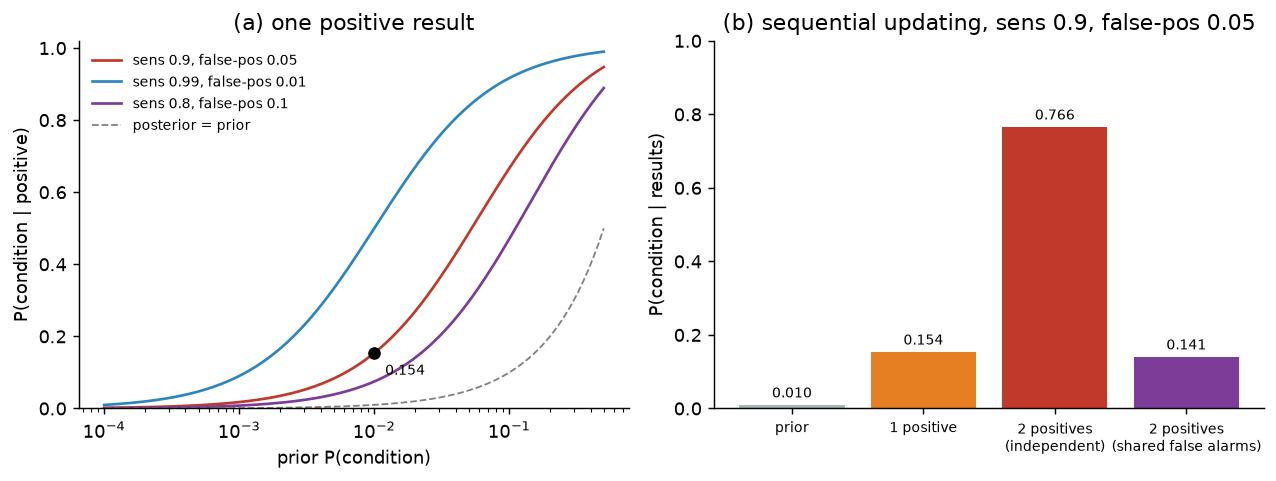

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
pg = np.logspace(-4, np.log10(0.5), 200)
for (sn, f), col in zip([(0.9, 0.05), (0.99, 0.01), (0.8, 0.10)], ["#c0392b", "#2e86c1", "#7d3c98"]):
    ax[0].plot(pg, [s.bayes(float(p), sn, f)["posterior"] for p in pg], color=col,
               label=f"sens {sn:g}, false-pos {f:g}")
ax[0].plot(pg, pg, color="gray", ls="--", lw=1, label="posterior = prior")
ax[0].scatter([PRIOR], [p1], color="k", zorder=3)
ax[0].annotate(f"{p1:.3f}", (PRIOR, p1), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax[0].set(xscale="log", xlabel="prior P(condition)", ylabel="P(condition | positive)",
          title="(a) one positive result", ylim=(0, 1.02))
ax[0].legend(frameon=False, fontsize=8)
bars = [PRIOR, p1, p2, true_corr]
names = ["prior", "1 positive", "2 positives\n(independent)", "2 positives\n(shared false alarms)"]
ax[1].bar(names, bars, color=["#aab7b8", "#e67e22", "#c0392b", "#7d3c98"])
for i, b in enumerate(bars):
    ax[1].text(i, b + 0.02, f"{b:.3f}", ha="center", fontsize=8)
ax[1].set(ylabel="P(condition | results)", ylim=(0, 1), title="(b) sequential updating, sens 0.9, false-pos 0.05")
ax[1].tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()

## Going deeper

### Bayes' rule

For condition $D$ and positive result $+$,

$$P(D\mid +)=\frac{P(+\mid D)\,P(D)}{P(+\mid D)\,P(D)+P(+\mid \bar D)\,P(\bar D)}, \qquad P(+)>0 .$$

### Odds form

With prior odds $O(D)=P(D)/P(\bar D)$ and likelihood ratio $\Lambda_+=P(+\mid D)/P(+\mid\bar D)$,

$$O(D\mid +)=\Lambda_+\,O(D).$$

### Two tests

In general $O(D\mid +_1,+_2)=\dfrac{P(+_1,+_2\mid D)}{P(+_1,+_2\mid\bar D)}\,O(D)$. The joint likelihood factorizes only if $+_1\perp +_2\mid D$ and $+_1\perp +_2\mid\bar D$. Then $O(D\mid +_1,+_2)=\Lambda_{+,1}\Lambda_{+,2}\,O(D)$. In the shared-trait example, $P(+_1,+_2\mid\bar D)=0.05$ instead of $0.05^2$. So the joint likelihood ratio is $0.81/0.05=16.2$, smaller than the single-test value 18.

### Negative results

$P(D\mid -)=\dfrac{(1-\text{sens})P(D)}{(1-\text{sens})P(D)+(1-\text{fp})P(\bar D)}$, which is `s.bayes(prior, 1 - sens, 1 - fp)`.

## Exercises

:::{admonition} Exercise: :label: lab2-ex1
:class: tip
A screening test has sensitivity 0.99 and false-positive rate 0.01. The condition has prior 0.001. What is $P(D\mid +)$?
:::

:::{dropdown} Solution
$0.00099/(0.00099+0.00999)\approx0.090$. When the base rate is 1 in 1,000, even an accurate-looking test gives mostly false alarms.
:::

:::{admonition} Exercise: :label: lab2-ex2
:class: tip
The prior is 0.01 and the sensitivity is 0.9. Which false-positive rate makes $P(D\mid+)=0.5$?
:::

:::{dropdown} Solution
Set true and false positives equal: $0.01\times0.9=0.99\,f$, so $f=0.009/0.99\approx0.0091$.
:::

:::{admonition} Exercise: :label: lab2-ex3
:class: tip
Use the lab's default test (prior 0.01, sensitivity 0.9, false-positive 0.05). What is $P(D\mid -)$ after a negative result?
:::

:::{dropdown} Solution
`s.bayes(0.01, 0.1, 0.95)` gives $0.001/(0.001+0.9405)\approx0.00106$. That is about a tenth of the prior.
:::

## Check yourself

In [11]:
e1 = s.bayes(0.001, 0.99, 0.01)["posterior"]
assert abs(e1 - 0.00099 / (0.00099 + 0.00999)) < 1e-12 and abs(e1 - 0.090) < 0.001

f_star = 0.01 * 0.9 / 0.99
assert abs(f_star - 0.0091) < 1e-4
assert math.isclose(s.bayes(0.01, 0.9, f_star)["posterior"], 0.5)

e3 = s.bayes(0.01, 0.1, 0.95)["posterior"]
assert math.isclose(e3, 0.001 / (0.001 + 0.9405)) and abs(e3 - 0.00106) < 1e-5

assert math.isclose(LR, 18.0) and math.isclose(0.81 / 0.05, 16.2) and 0.81 / 0.05 < LR   # joint LR with shared false alarms
for prior, sn, f in [(0.3, 0.7, 0.2), (0.05, 0.95, 0.1)]:          # counts always add up
    cnt = natural_frequencies(prior, sn, f)
    assert sum(cnt[k] for k in ("tp", "fn", "fp", "tn")) == N
print("All checks passed.")

All checks passed.


:::{note} Limits of this model
- Sensitivity and false-positive rate are treated as fixed numbers that apply to everyone in this group. In practice they vary with people, settings, and how the condition is defined.
- The prior must describe the group the person comes from. A person tested because of symptoms belongs to a group with a different base rate.
- Natural-frequency counts are rounded to whole people. For some settings they can differ slightly from the exact engine posterior.
- Sequential updating assumes the tests are conditionally independent given condition status. Shared causes of error break it.
:::